# DL — Transformer: OHLCV vs OHLCV + Indicators
### TCS Stock Price Prediction | Deep Learning — Transformer Encoder
**Target:** Predict next-day RETURN (back-converted to price for all metrics & graphs)
**Two Sets:** Set A (OHLCV, 5 features) · Set B (OHLCV + 9 Indicators, 14 features)
**Flow:** EDA -> Part A (OHLCV) -> Compute Indicators -> Part B -> Compare A vs B


## Why Transformer for Stock Price Prediction?
> **Transformer Encoders** use multi-head self-attention to capture dependencies across ALL positions in the sequence simultaneously — unlike RNNs which process sequentially.
> - Attention mechanisms allow the model to focus on the most relevant past days regardless of distance.
> - **Architecture:** Dense projection(32) -> Positional Encoding -> 2x Encoder Blocks (4-head MHA, FF=64, dropout 0.1, LayerNorm) -> GlobalAveragePooling1D -> Dense(16) -> Dense(1).
> - Vaswani et al. (2017) introduced Transformers; Wen & Liu (2023) applied them to financial time-series successfully.


In [1]:
# Dependencies ready
print('Environment ready!')


Environment ready!


---
## Step 0: Reproducibility — Set All Random Seeds to 42
Setting `numpy`, `python random`, and `tensorflow` seeds to **42** for fully reproducible results.


In [2]:
import os, random
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['PYTHONHASHSEED'] = '42'
random.seed(42)

import numpy as np
np.random.seed(42)

import tensorflow as tf
tf.random.set_seed(42)

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Dense, Dropout, Conv1D, MaxPooling1D, GlobalAveragePooling1D,
    Flatten, BatchNormalization, Input, MultiHeadAttention,
    LayerNormalization, Add
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('All imports done! TensorFlow version:', tf.__version__)
print('All random seeds set to 42.')


All imports done! TensorFlow version: 2.21.0
All random seeds set to 42.


---
## Step 1: Load TCS Dataset
Reading `TCS.csv` (skiprows=[1,2]), parsing date index, keeping OHLCV columns, dropping NaN rows.


In [3]:
df = pd.read_csv('TCS.csv', skiprows=[1, 2])
if 'Price' in df.columns:
    df.rename(columns={'Price': 'Date'}, inplace=True)
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)
df = df.sort_index()[['Open', 'High', 'Low', 'Close', 'Volume']]

for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.dropna(inplace=True)
print(f'Shape: {df.shape}')
print(f'Date range: {df.index.min().date()} to {df.index.max().date()}')
df.head()


Shape: (5363, 5)
Date range: 2005-01-03 to 2026-09-23


,Open,High,Low,Close,Volume
Date,,,,,
2005-01-03,106.848522,108.547908,106.848522,108.272682,4734168
2005-01-04,108.011891,108.331926,106.664545,107.312614,4979104
2005-01-05,107.227811,107.227811,102.435290,106.011681,9604320
2005-01-06,105.611652,107.691881,103.411409,105.648453,8006888
2005-01-07,106.411749,107.611881,105.024398,107.208633,7623136


In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print(f'Volume == 0: {(df["Volume"] == 0).sum()} rows')


Missing values per column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Volume == 0: 9 rows


In [5]:
print('Dataset Statistics:')
display(df.describe().round(2))


Dataset Statistics:


,Open,High,Low,Close,Volume
count,5363.00,5363.00,5363.00,5363.00,5363.00
mean,1344.44,1357.71,1330.29,1343.67,3350520.35
std,1188.95,1199.08,1178.30,1188.29,2819411.07
min,75.80,78.58,69.43,75.49,0.00
25%,274.27,277.70,270.58,274.01,1853218.00
50%,959.55,967.05,951.04,958.63,2650784.00
75%,2383.67,2414.17,2349.66,2376.28,3987019.00
max,4251.38,4266.48,4191.92,4230.71,88067154.00


---
## Step 2: Exploratory Data Analysis (EDA)
**Graphs:** Close price history | Candlestick (last 200 days) | Volume bar | OHLC line chart.


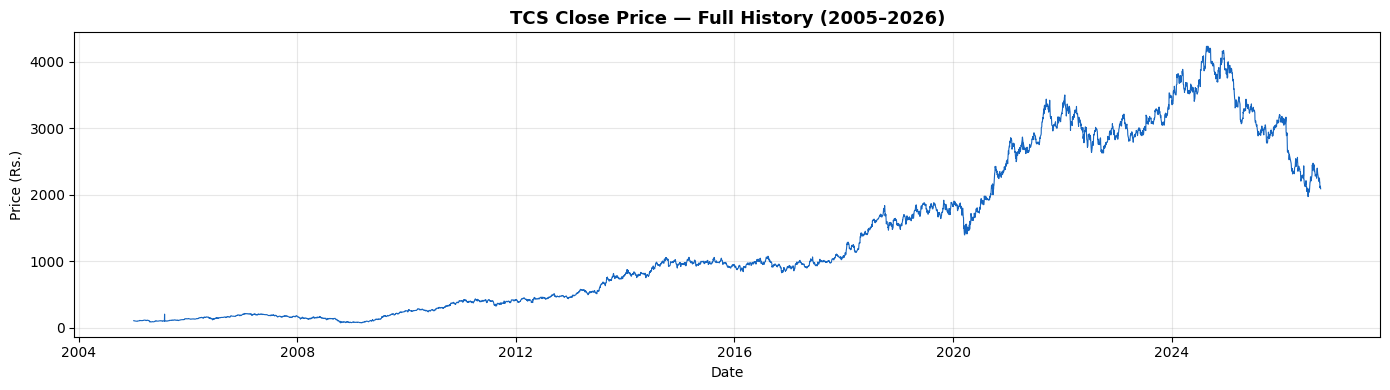

In [6]:
plt.figure(figsize=(14, 4))
plt.plot(df['Close'], color='#1565C0', lw=0.8)
plt.title('TCS Close Price — Full History (2005–2026)', fontsize=13, fontweight='bold')
plt.xlabel('Date'); plt.ylabel('Price (Rs.)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


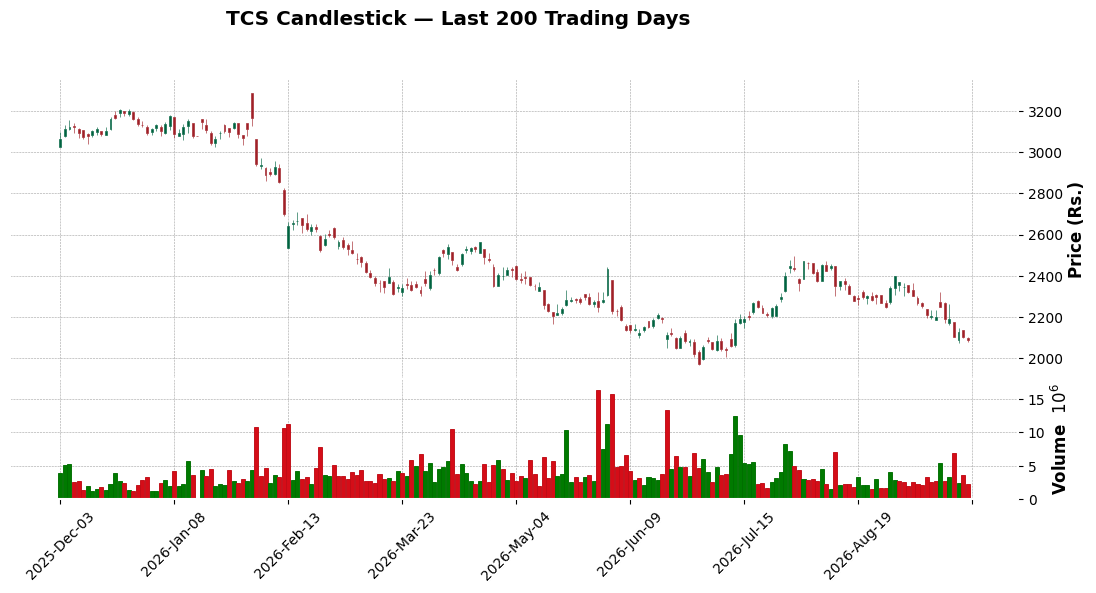

In [7]:
candle_df = df.tail(200).copy()
candle_df.index = pd.DatetimeIndex(candle_df.index)
mpf.plot(candle_df, type='candle', style='charles',
         title='TCS Candlestick — Last 200 Trading Days',
         ylabel='Price (Rs.)', volume=True,
         figsize=(14, 6), warn_too_much_data=400)


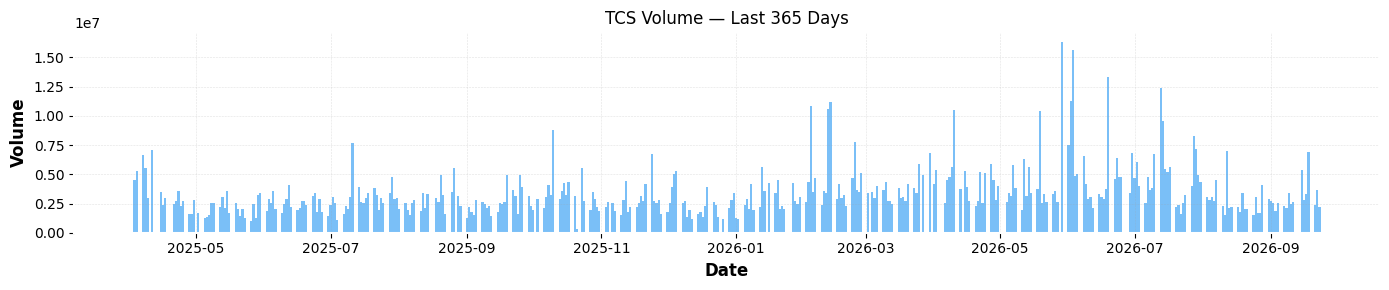

In [8]:
vol_df = df.tail(365)
plt.figure(figsize=(14, 3))
plt.bar(vol_df.index, vol_df['Volume'], color='#42A5F5', alpha=0.7, width=1)
plt.title('TCS Volume — Last 365 Days')
plt.xlabel('Date'); plt.ylabel('Volume')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


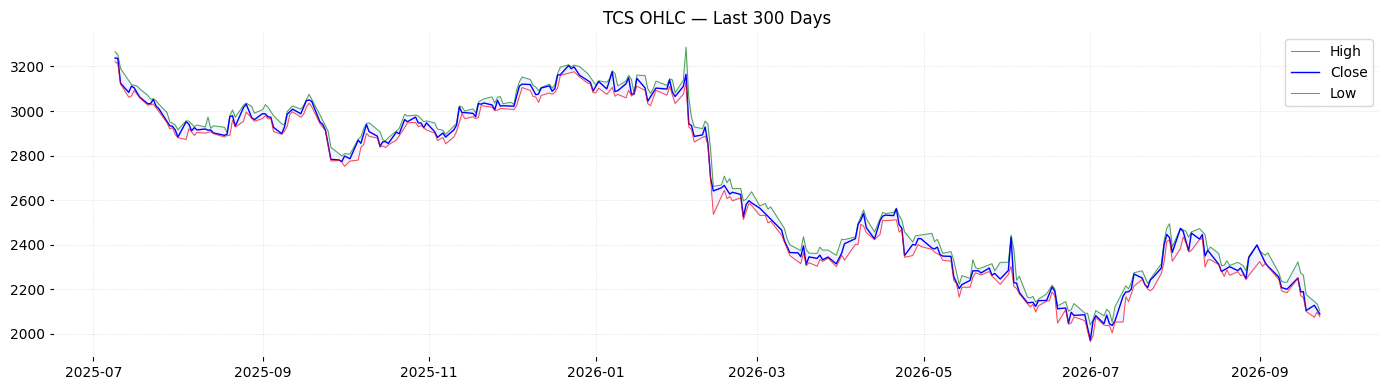

In [9]:
ohlc_df = df.tail(300)
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ohlc_df.index, ohlc_df['High'],  label='High',  color='green', lw=0.7, alpha=0.7)
ax.plot(ohlc_df.index, ohlc_df['Close'], label='Close', color='blue',  lw=1.0)
ax.plot(ohlc_df.index, ohlc_df['Low'],   label='Low',   color='red',   lw=0.7, alpha=0.7)
ax.fill_between(ohlc_df.index, ohlc_df['Low'], ohlc_df['High'], alpha=0.05, color='blue')
ax.set_title('TCS OHLC — Last 300 Days'); ax.legend()
ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
## Step 3: Define Return Target & Train-Test Split (80/20)
**Target:** `y_ret = Next_Close / Close - 1` (next-day simple return, NOT raw price)  
**Split:** ~4296 train rows | ~1067 test rows — same as ML notebooks.  
First test sequence allowed to look back into train end (past data, not leakage).


In [10]:
LOOK_BACK = 60
SET_A     = ['Open', 'High', 'Low', 'Close', 'Volume']

df_work = df.copy()
df_work['Next_Close'] = df_work['Close'].shift(-1)
df_work['Target_Ret'] = df_work['Next_Close'] / df_work['Close'] - 1

close_series = df_work['Close'].copy()
next_series  = df_work['Next_Close'].copy()
ret_series   = df_work['Target_Ret'].copy()

valid_idx   = ret_series.dropna().index
df_A        = df_work.loc[valid_idx, SET_A].copy()
y_ret_A     = ret_series.loc[valid_idx].values
close_A     = close_series.loc[valid_idx].values
next_A      = next_series.loc[valid_idx].values
X_A         = df_A[SET_A].values

n_tr = int(len(X_A) * 0.8)
X_A_train, X_A_test       = X_A[:n_tr],     X_A[n_tr:]
y_A_train, y_A_test       = y_ret_A[:n_tr], y_ret_A[n_tr:]
close_A_train, close_A_test = close_A[:n_tr], close_A[n_tr:]
next_A_train,  next_A_test  = next_A[:n_tr],  next_A[n_tr:]

print(f'Total rows: {len(X_A)}')
print(f'Train: {X_A_train.shape}  |  Test: {X_A_test.shape}')
print(f'y_A_train stats -> mean={y_A_train.mean():.4f}  std={y_A_train.std():.4f}')


Total rows: 5362
Train: (4289, 5)  |  Test: (1073, 5)
y_A_train stats -> mean=0.0011  std=0.0258


### Data Inspection — Set A Stats


In [11]:
print('Set A — OHLCV (5 features)')
display(pd.DataFrame(X_A, columns=SET_A).describe().round(2))


Set A — OHLCV (5 features)


,Open,High,Low,Close,Volume
count,5362.00,5362.00,5362.00,5362.00,5362.00
mean,1344.30,1357.57,1330.15,1343.53,3350729.62
std,1189.01,1199.15,1178.37,1188.35,2819632.36
min,75.80,78.58,69.43,75.49,0.00
25%,274.19,277.67,270.52,273.96,1853135.00
50%,959.50,967.02,951.01,958.52,2650817.00
75%,2383.78,2414.21,2350.58,2376.92,3987605.50
max,4251.38,4266.48,4191.92,4230.71,88067154.00


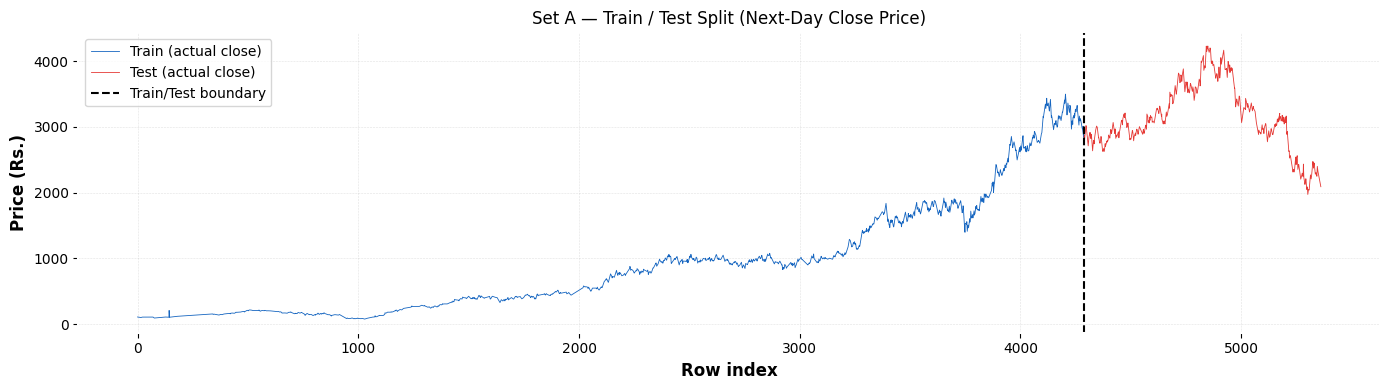

In [12]:
n_te = len(next_A_test)
plt.figure(figsize=(14, 4))
plt.plot(range(n_tr), next_A_train, color='#1565C0', lw=0.6, label='Train (actual close)')
plt.plot(range(n_tr, n_tr+n_te), next_A_test, color='#E53935', lw=0.6, label='Test (actual close)')
plt.axvline(n_tr, color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Set A — Train / Test Split (Next-Day Close Price)')
plt.xlabel('Row index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part A: Transformer Encoder — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


---
---
# Part A: Transformer Encoder — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [13]:
scaler_XA = StandardScaler()
X_A_tr_sc = scaler_XA.fit_transform(X_A_train)
X_A_te_sc = scaler_XA.transform(X_A_test)

scaler_yA = StandardScaler()
y_A_tr_sc = scaler_yA.fit_transform(y_A_train.reshape(-1, 1)).flatten()
y_A_te_sc = scaler_yA.transform(y_A_test.reshape(-1, 1)).flatten()

print('Feature scaler fitted on train only.')
print('Target  scaler fitted on train only.')


Feature scaler fitted on train only.
Target  scaler fitted on train only.


---
---
# Part A: Transformer Encoder — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [14]:
def create_seq(X_sc, y_sc, lb=60):
    Xs, ys = [], []
    for i in range(lb, len(X_sc)):
        Xs.append(X_sc[i-lb:i]); ys.append(y_sc[i])
    return np.array(Xs, dtype='float32'), np.array(ys, dtype='float32')

X_A_joined = np.vstack([X_A_tr_sc[-LOOK_BACK:], X_A_te_sc])
y_A_joined = np.concatenate([y_A_tr_sc[-LOOK_BACK:], y_A_te_sc])

X_A_tr_seq, y_A_tr_seq = create_seq(X_A_tr_sc, y_A_tr_sc)
X_A_te_seq, y_A_te_seq = create_seq(X_A_joined, y_A_joined)

print(f'Train sequences: {X_A_tr_seq.shape}')
print(f'Test  sequences: {X_A_te_seq.shape}')


Train sequences: (4229, 60, 5)
Test  sequences: (1073, 60, 5)


---
---
# Part A: Transformer Encoder — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [15]:
import tensorflow as tf

def transformer_encoder(inputs, num_heads, ff_dim, dropout=0.1):
    # Multi-head self-attention
    attn_output = MultiHeadAttention(num_heads=num_heads, key_dim=inputs.shape[-1]//num_heads)(inputs, inputs)
    attn_output = Dropout(dropout)(attn_output)
    out1 = LayerNormalization(epsilon=1e-6)(Add()([inputs, attn_output]))
    # Feed-forward
    ff = Dense(ff_dim, activation='relu')(out1)
    ff = Dense(inputs.shape[-1])(ff)
    ff = Dropout(dropout)(ff)
    out2 = LayerNormalization(epsilon=1e-6)(Add()([out1, ff]))
    return out2

def build_model(timesteps, n_feat):
    inputs = Input(shape=(timesteps, n_feat))
    # Project to 32 dims
    x = Dense(32)(inputs)
    # Simple positional encoding (learnable)
    pos_enc = tf.keras.layers.Embedding(input_dim=timesteps, output_dim=32)(
        tf.range(start=0, limit=timesteps, delta=1)
    )
    x = x + pos_enc
    # 2 Transformer encoder blocks
    x = transformer_encoder(x, num_heads=4, ff_dim=64, dropout=0.1)
    x = transformer_encoder(x, num_heads=4, ff_dim=64, dropout=0.1)
    # Pooling + head
    x = GlobalAveragePooling1D()(x)
    x = Dense(16, activation='relu')(x)
    outputs = Dense(1)(x)
    m = Model(inputs, outputs)
    m.compile(optimizer=Adam(0.001), loss='mse', metrics=['mae'])
    return m

model_A = build_model(LOOK_BACK, len(SET_A))
model_A.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 60, 5)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 60, 32)    │        192 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 60, 32)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 60, 32)    │      4,224 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 60, 32)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 60, 32)    │          0 │ add[0][0],        │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 60, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 60, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 60, 32)    │      2,080 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 60, 32)    │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 60, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 32)    │         64 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 60, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 60, 32)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 60, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 32)    │         64 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 60, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 60, 32)    │      2,080 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 60, 32)    │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 60, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_5[0][0] 

 Total params: 17,825 (69.63 KB)

 Trainable params: 17,825 (69.63 KB)

 Non-trainable params: 0 (0.00 B)

---
---
# Part A: Transformer Encoder — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [16]:
cb = [
    EarlyStopping(patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=7, verbose=1)
]

history_A = model_A.fit(
    X_A_tr_seq, y_A_tr_seq,
    epochs=100, batch_size=32,
    validation_split=0.1,
    callbacks=cb, verbose=1
)


Epoch 1/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - loss: 1.1431 - mae: 0.5848 - val_loss: 0.3341 - val_mae: 0.4208 - learning_rate: 0.0010
Epoch 2/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 1.1043 - mae: 0.5649 - val_loss: 0.3249 - val_mae: 0.4119 - learning_rate: 0.0010
Epoch 3/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 1.1010 - mae: 0.5641 - val_loss: 0.3250 - val_mae: 0.4119 - learning_rate: 0.0010
Epoch 4/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 1.0979 - mae: 0.5618 - val_loss: 0.3250 - val_mae: 0.4119 - learning_rate: 0.0010
Epoch 5/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 1.0980 - mae: 0.5621 - val_loss: 0.3250 - val_mae: 0.4119 - learning_rate: 0.0010
Epoch 6/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 1.0966 - mae: 0.5615 - val_loss: 0.3250 - val_mae: 0.4120 - learning_rate: 0.0010
Epoch 7/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 1.0965 - mae: 0.5598 - val_loss: 0.3250 - val_mae: 0.4120 - learning_rate

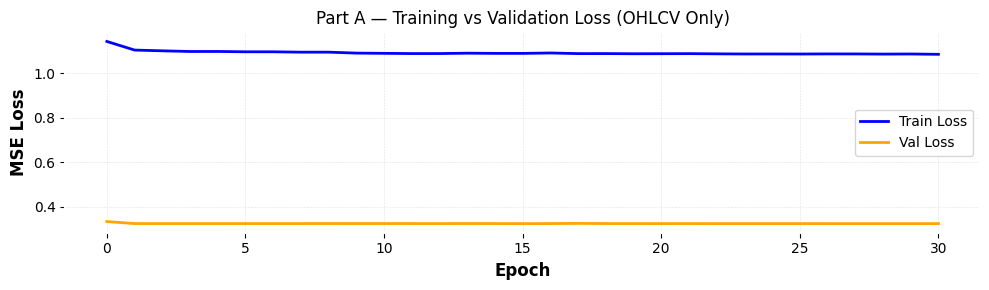

In [17]:
plt.figure(figsize=(10, 3))
plt.plot(history_A.history['loss'],     label='Train Loss', color='blue')
plt.plot(history_A.history['val_loss'], label='Val Loss',   color='orange')
plt.title('Part A — Training vs Validation Loss (OHLCV Only)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


### Train vs Validation Loss Curve — Interpretation
- **Converging curves (train ≈ val):** Model generalises well — **Good Fit**.
- **Large gap (train << val):** Validation loss much higher — **Overfitting**.
- **Both curves high / flat:** Model cannot capture patterns — **Underfitting**.
- Early stopping halts training once val loss stops improving, preventing runaway overfitting.


---
---
# Part A: Transformer Encoder — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [18]:
def get_metrics(y_true, y_pred, label=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    direction_actual = np.diff(y_true)
    direction_pred   = np.diff(y_pred)
    dir_acc = np.mean(np.sign(direction_actual) == np.sign(direction_pred)) * 100
    if label:
        print(f'  {label}')
        print(f'  MAE   : {mae:.4f}  Rs.')
        print(f'  RMSE  : {rmse:.4f}  Rs.')
        print(f'  R2    : {r2:.4f}')
        print(f'  MAPE  : {mape:.4f} %')
        print(f'  DirAcc: {dir_acc:.2f} %')
    return dict(MAE=mae, RMSE=rmse, R2=r2, MAPE=mape, DirAcc=dir_acc)


In [19]:
y_pred_ret_A_sc = model_A.predict(X_A_te_seq, verbose=0).flatten()
y_pred_ret_A    = scaler_yA.inverse_transform(y_pred_ret_A_sc.reshape(-1, 1)).flatten()
y_pred_A        = close_A_test * (1 + y_pred_ret_A)
y_actual_A      = next_A_test

print(f'Test samples predicted: {len(y_pred_A)}')
print(f'Sample actual  prices: {y_actual_A[:5].round(2)}')
print(f'Sample predicted prices: {y_pred_A[:5].round(2)}')

print('='*55)
print('  Test Metrics — Part A (OHLCV only)')
print('='*55)
met_A_test = get_metrics(y_actual_A, y_pred_A, label='Part A — Test')


Test samples predicted: 1073
Sample actual  prices: [2866.79 2780.46 2832.51 2862.66 2962.69]
Sample predicted prices: [2898.38 2868.93 2782.53 2834.62 2864.79]
  Test Metrics — Part A (OHLCV only)
  Part A — Test
  MAE   : 31.3557  Rs.
  RMSE  : 43.5986  Rs.
  R2    : 0.9924
  MAPE  : 1.0213 %
  DirAcc: 50.56 %


In [20]:
dates_A = df_A.index[n_tr:]
naive_pred_A = close_A_test

comparison_A = pd.DataFrame({
    'Date'              : dates_A,
    'Actual Next Close' : y_actual_A.round(2),
    'Naive (Close_t)'   : naive_pred_A.round(2),
    'Model Predicted'   : y_pred_A.round(2),
    'Error'             : (y_pred_A - y_actual_A).round(2),
})
comparison_A.set_index('Date', inplace=True)
print('Set A — First 10 Test-Day Comparison:')
display(comparison_A.head(10))


Set A — First 10 Test-Day Comparison:


,Actual Next Close,Naive (Close_t),Model Predicted,Error
Date,,,,
2022-05-23,2866.79,2896.22,2898.38,31.59
2022-05-24,2780.46,2866.79,2868.93,88.46
2022-05-25,2832.51,2780.46,2782.53,-49.99
2022-05-26,2862.66,2832.51,2834.62,-28.05
2022-05-27,2962.69,2862.66,2864.79,-97.90
2022-05-30,2953.12,2962.69,2964.88,11.77
2022-05-31,2945.09,2953.12,2955.31,10.22
2022-06-01,3004.60,2945.09,2947.27,-57.33
2022-06-02,3019.65,3004.60,3006.83,-12.82


---
---
# Part A: Transformer Encoder — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


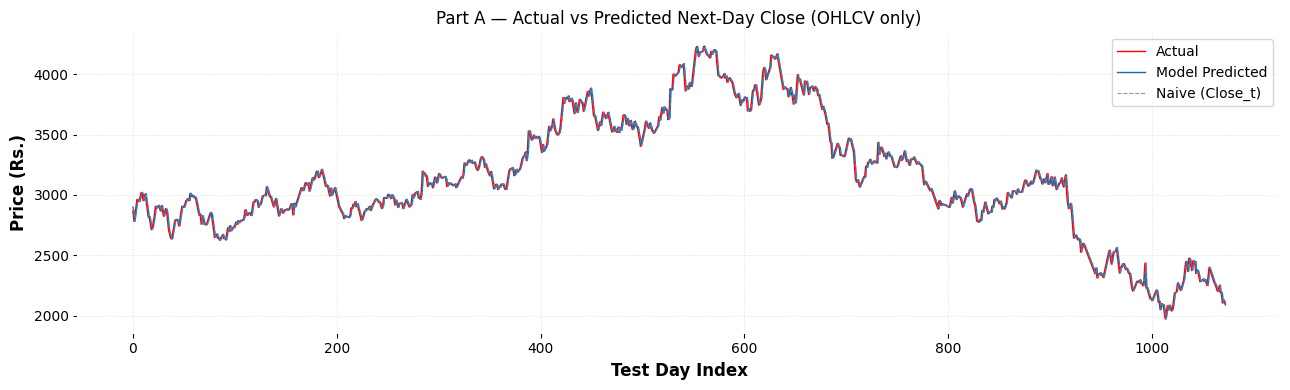

In [21]:
plt.figure(figsize=(13, 4))
plt.plot(y_actual_A,   color='red',     lw=1.0, label='Actual')
plt.plot(y_pred_A,     color='#1565C0', lw=1.0, label='Model Predicted')
plt.plot(naive_pred_A, color='gray',    lw=0.8, linestyle='--', alpha=0.8, label='Naive (Close_t)')
plt.title('Part A — Actual vs Predicted Next-Day Close (OHLCV only)')
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


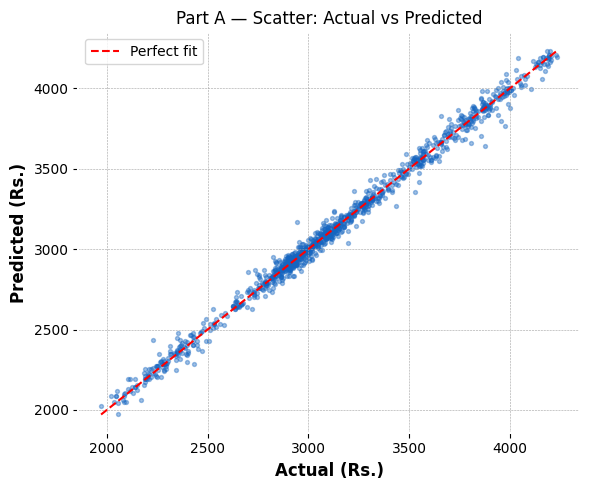

In [22]:
plt.figure(figsize=(6, 5))
plt.scatter(y_actual_A, y_pred_A, alpha=0.4, s=8, color='#1565C0')
mn, mx = min(y_actual_A.min(), y_pred_A.min()), max(y_actual_A.max(), y_pred_A.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect fit')
plt.title('Part A — Scatter: Actual vs Predicted')
plt.xlabel('Actual (Rs.)'); plt.ylabel('Predicted (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


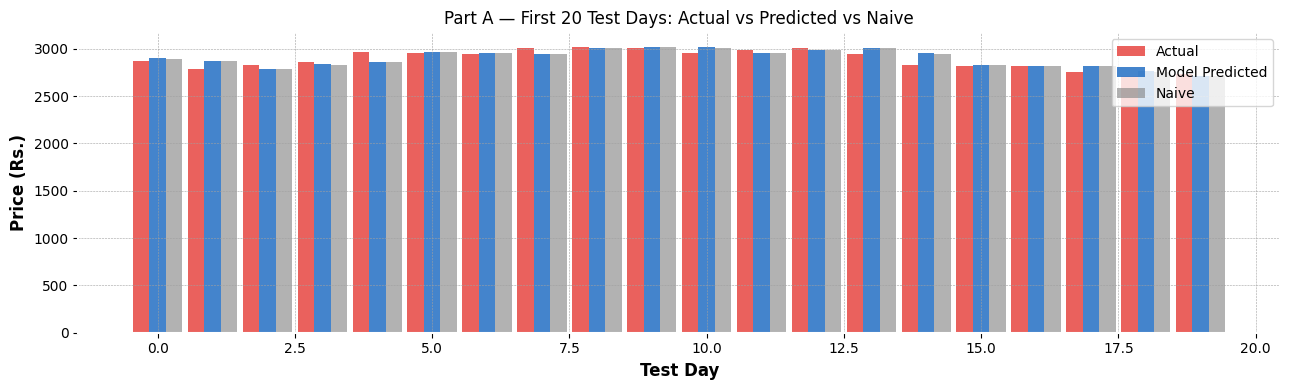

In [23]:
x_pos = np.arange(20)
plt.figure(figsize=(13, 4))
plt.bar(x_pos-0.3,  y_actual_A[:20],   0.3, label='Actual',         color='#E53935', alpha=0.8)
plt.bar(x_pos,      y_pred_A[:20],     0.3, label='Model Predicted', color='#1565C0', alpha=0.8)
plt.bar(x_pos+0.3,  naive_pred_A[:20], 0.3, label='Naive',           color='gray',    alpha=0.6)
plt.title('Part A — First 20 Test Days: Actual vs Predicted vs Naive')
plt.xlabel('Test Day'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


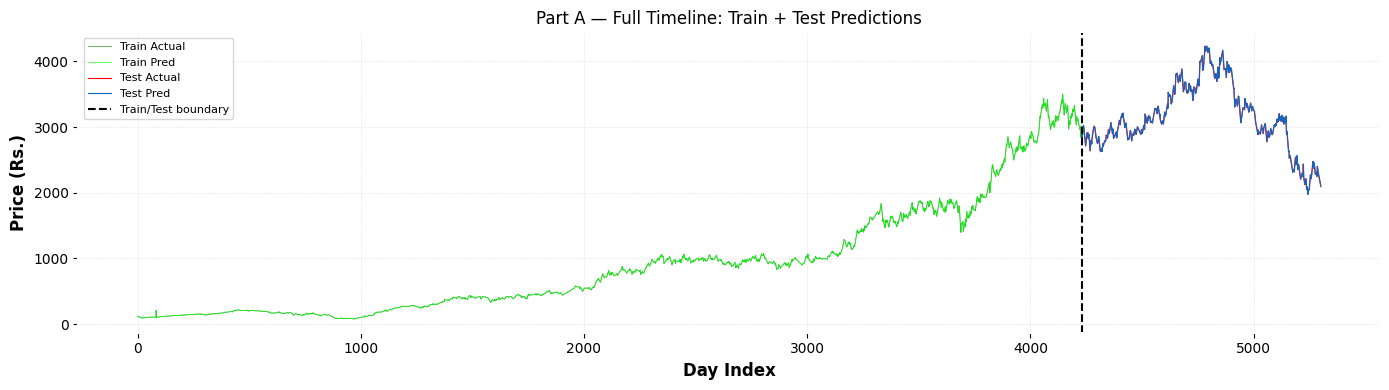

In [24]:
y_tr_pred_ret_A_sc = model_A.predict(X_A_tr_seq, verbose=0).flatten()
y_tr_pred_ret_A    = scaler_yA.inverse_transform(y_tr_pred_ret_A_sc.reshape(-1,1)).flatten()
y_tr_pred_A  = close_A_train[LOOK_BACK:] * (1 + y_tr_pred_ret_A)
y_tr_act_A   = next_A_train[LOOK_BACK:]

plt.figure(figsize=(14, 4))
plt.plot(range(len(y_tr_act_A)), y_tr_act_A,  color='green', lw=0.6, alpha=0.7, label='Train Actual')
plt.plot(range(len(y_tr_act_A)), y_tr_pred_A, color='lime',  lw=0.6, alpha=0.7, label='Train Pred')
plt.plot(range(len(y_tr_act_A), len(y_tr_act_A)+len(y_actual_A)), y_actual_A, color='red',     lw=0.8, label='Test Actual')
plt.plot(range(len(y_tr_act_A), len(y_tr_act_A)+len(y_pred_A)),   y_pred_A,   color='#1565C0', lw=0.8, label='Test Pred')
plt.axvline(len(y_tr_act_A), color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Part A — Full Timeline: Train + Test Predictions')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part A: Transformer Encoder — Set A (OHLCV Only, 5 Features)
**Features:** Open, High, Low, Close, Volume  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [25]:
tr_met_A = get_metrics(y_tr_act_A, y_tr_pred_A)

train_mape_A = tr_met_A['MAPE']; test_mape_A = met_A_test['MAPE']
train_r2_A   = tr_met_A['R2'];   test_r2_A   = met_A_test['R2']

if test_mape_A > 1.5 * train_mape_A or (train_r2_A - test_r2_A) > 0.05:
    verdict_A = 'OVERFIT'
elif train_r2_A < 0.80:
    verdict_A = 'UNDERFIT'
else:
    verdict_A = 'GOOD FIT'

print('='*52)
print('  Overfit Check — Part A (OHLCV Only)')
print('='*52)
print(f'  Train MAPE : {train_mape_A:.4f}%    Test MAPE  : {test_mape_A:.4f}%')
print(f'  1.5x Train threshold : {1.5*train_mape_A:.4f}%')
print(f'  Train R2   : {train_r2_A:.4f}    Test R2    : {test_r2_A:.4f}')
print(f'  R2 gap     : {train_r2_A - test_r2_A:.4f}  (threshold 0.05)')
print(f'  Verdict    : {verdict_A}')


  Overfit Check — Part A (OHLCV Only)
  Train MAPE : 1.4010%    Test MAPE  : 1.0213%
  1.5x Train threshold : 2.1015%
  Train R2   : 0.9995    Test R2    : 0.9924
  R2 gap     : 0.0071  (threshold 0.05)
  Verdict    : GOOD FIT


---
## Step 4: Compute Technical Indicators (Feature Engineering for Set B)
| Indicator | Description |
|-----------|-------------|
| MA_7, MA_30 | 7-day and 30-day Moving Average |
| EMA_12, EMA_26 | Exponential Moving Averages |
| MACD | EMA_12 - EMA_26 |
| RSI_14 | 14-day Relative Strength Index |
| Daily Return | Day-over-day % change |
| Volatility | 14-day rolling std of returns |
| Lag1 Close | Yesterday's close price |


In [26]:
df2 = df.copy()
df2['MA_7']         = df2['Close'].rolling(7).mean()
df2['MA_30']        = df2['Close'].rolling(30).mean()
df2['EMA_12']       = df2['Close'].ewm(span=12, adjust=False).mean()
df2['EMA_26']       = df2['Close'].ewm(span=26, adjust=False).mean()
df2['MACD']         = df2['EMA_12'] - df2['EMA_26']

delta = df2['Close'].diff()
gain  = delta.where(delta > 0, 0).rolling(14).mean()
loss  = (-delta.where(delta < 0, 0)).rolling(14).mean()
df2['RSI_14'] = 100 - (100 / (1 + gain / loss))

df2['Daily_Return'] = df2['Close'].pct_change()
df2['Volatility']   = df2['Daily_Return'].rolling(14).std()
df2['Lag1_Close']   = df2['Close'].shift(1)

df2.dropna(inplace=True)
print(f'df2 shape after indicators: {df2.shape}')


df2 shape after indicators: (5334, 14)


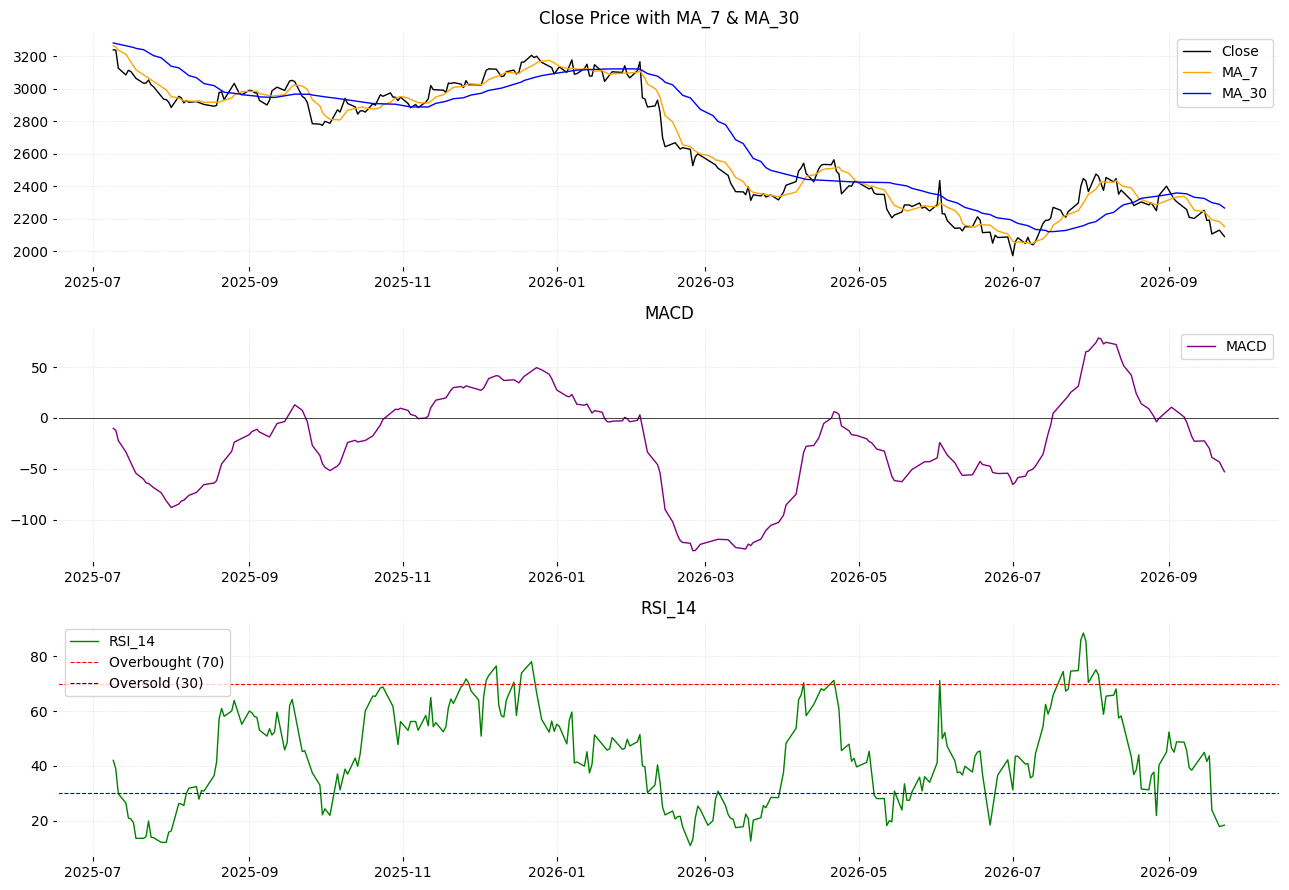

In [27]:
plot_df = df2.tail(300)
fig, axes = plt.subplots(3, 1, figsize=(13, 9))
axes[0].plot(plot_df.index, plot_df['Close'], label='Close', color='black', lw=1.0)
axes[0].plot(plot_df.index, plot_df['MA_7'],  label='MA_7',  color='orange', lw=1.0)
axes[0].plot(plot_df.index, plot_df['MA_30'], label='MA_30', color='blue',   lw=1.0)
axes[0].set_title('Close Price with MA_7 & MA_30'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(plot_df.index, plot_df['MACD'], label='MACD', color='purple', lw=1.0)
axes[1].axhline(0, color='black', lw=0.5); axes[1].set_title('MACD'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

axes[2].plot(plot_df.index, plot_df['RSI_14'], label='RSI_14', color='green', lw=1.0)
axes[2].axhline(70, color='red',  lw=0.8, linestyle='--', label='Overbought (70)')
axes[2].axhline(30, color='blue', lw=0.8, linestyle='--', label='Oversold (30)')
axes[2].set_title('RSI_14'); axes[2].legend(); axes[2].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


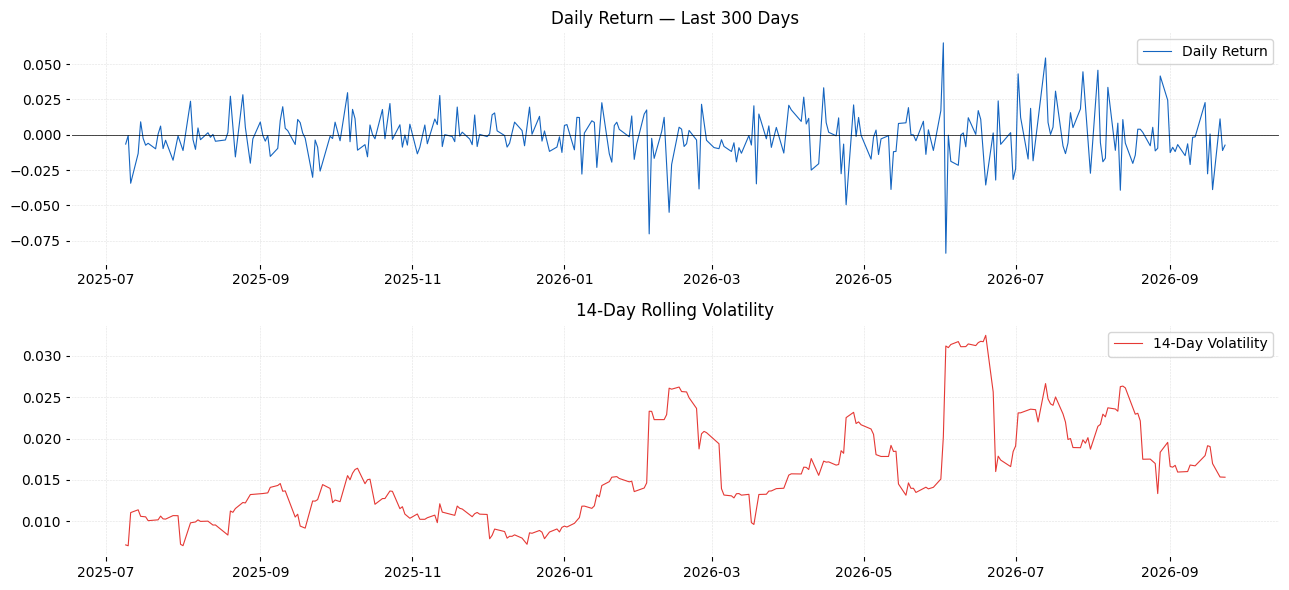

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6))
axes[0].plot(plot_df.index, plot_df['Daily_Return'], label='Daily Return', color='#1565C0', lw=0.8)
axes[0].axhline(0, color='black', lw=0.5)
axes[0].set_title('Daily Return — Last 300 Days'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(plot_df.index, plot_df['Volatility'], label='14-Day Volatility', color='#E53935', lw=0.8)
axes[1].set_title('14-Day Rolling Volatility'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


---
---
# Part B: Transformer Encoder — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [29]:
SET_B = ['Open','High','Low','Close','Volume',
         'MA_7','MA_30','EMA_12','EMA_26','MACD',
         'RSI_14','Daily_Return','Volatility','Lag1_Close']

df2['Next_Close'] = df2['Close'].shift(-1)
df2['Target_Ret'] = df2['Next_Close'] / df2['Close'] - 1

close_B_series = df2['Close'].copy()
next_B_series  = df2['Next_Close'].copy()
ret_B_series   = df2['Target_Ret'].copy()

valid_B_idx = ret_B_series.dropna().index.intersection(df2[SET_B].dropna().index)
df_B    = df2.loc[valid_B_idx, SET_B].copy()
y_ret_B = ret_B_series.loc[valid_B_idx].values
close_B = close_B_series.loc[valid_B_idx].values
next_B  = next_B_series.loc[valid_B_idx].values
X_B     = df_B[SET_B].values

n_tr_B = int(len(X_B) * 0.8)
X_B_train, X_B_test       = X_B[:n_tr_B],     X_B[n_tr_B:]
y_B_train, y_B_test       = y_ret_B[:n_tr_B], y_ret_B[n_tr_B:]
close_B_train, close_B_test = close_B[:n_tr_B], close_B[n_tr_B:]
next_B_train,  next_B_test  = next_B[:n_tr_B],  next_B[n_tr_B:]

print(f'Set B rows: {len(X_B)}  Train: {X_B_train.shape}  Test: {X_B_test.shape}')


Set B rows: 5333  Train: (4266, 14)  Test: (1067, 14)


### Data Inspection — Set B Stats


In [30]:
print('Set B — OHLCV + All Indicators (14 features)')
display(pd.DataFrame(X_B, columns=SET_B).describe().round(4))


Set B — OHLCV + All Indicators (14 features)


,Open,High,Low,Close,Volume,MA_7,MA_30,EMA_12,EMA_26,MACD,RSI_14,Daily_Return,Volatility,Lag1_Close
count,5333.0000,5333.0000,5333.0000,5333.0000,5.333000e+03,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000,5333.0000
mean,1351.0368,1364.3776,1336.8202,1350.2678,3.326257e+06,1349.1268,1344.4682,1348.1175,1345.2645,2.8529,52.6060,0.0008,0.0174,1349.8943
std,1188.7123,1198.8356,1178.0771,1188.0539,2.778885e+06,1187.9541,1187.5660,1187.6083,1187.0824,27.8976,16.4409,0.0240,0.0170,1188.1297
min,75.7952,78.5783,69.4271,75.4907,0.000000e+00,78.5964,82.7727,79.9551,81.5531,-136.3368,6.2275,-0.5061,0.0033,75.4907
25%,283.4482,287.5412,281.3501,284.6519,1.848566e+06,280.7168,275.5437,277.9242,274.1673,-4.1686,40.5633,-0.0085,0.0114,284.0500
50%,961.4397,969.2750,952.3013,959.8018,2.642976e+06,961.9839,964.5486,960.5972,963.5933,2.0157,52.9703,0.0003,0.0148,959.7253
75%,2392.5774,2426.0135,2364.7938,2396.5859,3.968866e+06,2393.1938,2384.2090,2381.7426,2371.4609,11.3143,64.6042,0.0096,0.0191,2396.5859
max,4251.3807,4266.4788,4191.9208,4230.7100,8.806715e+07,4194.6556,4134.2035,4176.5447,4132.3174,120.2778,97.5438,1.0000,0.3098,4230.7100


---
---
# Part B: Transformer Encoder — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [31]:
scaler_XB = StandardScaler()
X_B_tr_sc = scaler_XB.fit_transform(X_B_train)
X_B_te_sc = scaler_XB.transform(X_B_test)

scaler_yB = StandardScaler()
y_B_tr_sc = scaler_yB.fit_transform(y_B_train.reshape(-1, 1)).flatten()
y_B_te_sc = scaler_yB.transform(y_B_test.reshape(-1, 1)).flatten()
print('Scalers fitted on train only.')


Scalers fitted on train only.


---
---
# Part B: Transformer Encoder — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [32]:
X_B_joined = np.vstack([X_B_tr_sc[-LOOK_BACK:], X_B_te_sc])
y_B_joined = np.concatenate([y_B_tr_sc[-LOOK_BACK:], y_B_te_sc])

X_B_tr_seq, y_B_tr_seq = create_seq(X_B_tr_sc, y_B_tr_sc)
X_B_te_seq, y_B_te_seq = create_seq(X_B_joined, y_B_joined)
print(f'Train sequences: {X_B_tr_seq.shape}  Test: {X_B_te_seq.shape}')


Train sequences: (4206, 60, 14)  Test: (1067, 60, 14)


---
---
# Part B: Transformer Encoder — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [33]:
import tensorflow as tf

def transformer_encoder(inputs, num_heads, ff_dim, dropout=0.1):
    # Multi-head self-attention
    attn_output = MultiHeadAttention(num_heads=num_heads, key_dim=inputs.shape[-1]//num_heads)(inputs, inputs)
    attn_output = Dropout(dropout)(attn_output)
    out1 = LayerNormalization(epsilon=1e-6)(Add()([inputs, attn_output]))
    # Feed-forward
    ff = Dense(ff_dim, activation='relu')(out1)
    ff = Dense(inputs.shape[-1])(ff)
    ff = Dropout(dropout)(ff)
    out2 = LayerNormalization(epsilon=1e-6)(Add()([out1, ff]))
    return out2

def build_model(timesteps, n_feat):
    inputs = Input(shape=(timesteps, n_feat))
    # Project to 32 dims
    x = Dense(32)(inputs)
    # Simple positional encoding (learnable)
    pos_enc = tf.keras.layers.Embedding(input_dim=timesteps, output_dim=32)(
        tf.range(start=0, limit=timesteps, delta=1)
    )
    x = x + pos_enc
    # 2 Transformer encoder blocks
    x = transformer_encoder(x, num_heads=4, ff_dim=64, dropout=0.1)
    x = transformer_encoder(x, num_heads=4, ff_dim=64, dropout=0.1)
    # Pooling + head
    x = GlobalAveragePooling1D()(x)
    x = Dense(16, activation='relu')(x)
    outputs = Dense(1)(x)
    m = Model(inputs, outputs)
    m.compile(optimizer=Adam(0.001), loss='mse', metrics=['mae'])
    return m

model_B = build_model(LOOK_BACK, len(SET_B))
model_B.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 60, 14)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 60, 32)    │        480 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 60, 32)    │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 60, 32)    │      4,224 │ add_5[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_5[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 60, 32)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 60, 32)    │          0 │ add_5[0][0],      │
│                     │                   │            │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 32)    │         64 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 60, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 60, 32)    │      2,080 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 60, 32)    │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 60, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 32)    │         64 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 60, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 60, 32)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 60, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 32)    │         64 │ add_8[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 60, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 60, 32)    │      2,080 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 60, 32)    │          0 │ dense_11[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 18,113 (70.75 KB)

 Trainable params: 18,113 (70.75 KB)

 Non-trainable params: 0 (0.00 B)

---
---
# Part B: Transformer Encoder — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [34]:
history_B = model_B.fit(
    X_B_tr_seq, y_B_tr_seq,
    epochs=100, batch_size=32,
    validation_split=0.1,
    callbacks=cb, verbose=1
)


Epoch 1/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 11s 38ms/step - loss: 1.1106 - mae: 0.5675 - val_loss: 0.3259 - val_mae: 0.4141 - learning_rate: 0.0010
Epoch 2/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 1.0925 - mae: 0.5583 - val_loss: 0.3274 - val_mae: 0.4150 - learning_rate: 0.0010
Epoch 3/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 1.0901 - mae: 0.5572 - val_loss: 0.3326 - val_mae: 0.4191 - learning_rate: 0.0010
Epoch 4/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - loss: 1.0877 - mae: 0.5560 - val_loss: 0.3337 - val_mae: 0.4200 - learning_rate: 0.0010
Epoch 5/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 1.0885 - mae: 0.5559 - val_loss: 0.3620 - val_mae: 0.4461 - learning_rate: 0.0010
Epoch 6/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 1.0846 - mae: 0.5546 - val_loss: 0.3567 - val_mae: 0.4415 - learning_rate: 0.0010
Epoch 7/100
119/119 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 1.0858 - mae: 0.5552 - val_loss: 0.3480 - val_mae: 0.4334 - learning_rate

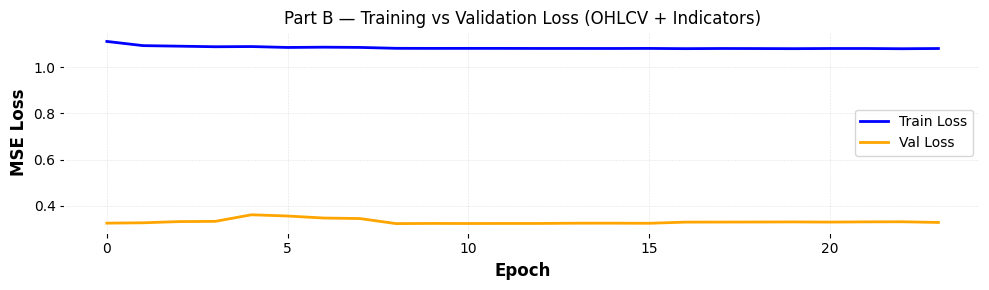

In [35]:
plt.figure(figsize=(10, 3))
plt.plot(history_B.history['loss'],     label='Train Loss', color='blue')
plt.plot(history_B.history['val_loss'], label='Val Loss',   color='orange')
plt.title('Part B — Training vs Validation Loss (OHLCV + Indicators)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


### Train vs Validation Loss — Interpretation
Converging curves = Good Fit. Growing gap (train falls, val stagnates) = Overfitting.
Early stopping fires when val loss stops improving.


---
---
# Part B: Transformer Encoder — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [36]:
y_pred_ret_B_sc = model_B.predict(X_B_te_seq, verbose=0).flatten()
y_pred_ret_B    = scaler_yB.inverse_transform(y_pred_ret_B_sc.reshape(-1, 1)).flatten()
y_pred_B   = close_B_test * (1 + y_pred_ret_B)
y_actual_B = next_B_test

print(f'Test samples predicted: {len(y_pred_B)}')
print('='*55)
met_B_test = get_metrics(y_actual_B, y_pred_B, label='Part B — Test')


Test samples predicted: 1067
  Part B — Test
  MAE   : 31.1110  Rs.
  RMSE  : 43.4138  Rs.
  R2    : 0.9925
  MAPE  : 1.0126 %
  DirAcc: 50.47 %


In [37]:
dates_B = df_B.index[n_tr_B:]
naive_pred_B = close_B_test

comparison_B = pd.DataFrame({
    'Date'              : dates_B,
    'Actual Next Close' : y_actual_B.round(2),
    'Naive (Close_t)'   : naive_pred_B.round(2),
    'Model Predicted'   : y_pred_B.round(2),
    'Error'             : (y_pred_B - y_actual_B).round(2),
})
comparison_B.set_index('Date', inplace=True)
print('Set B — First 10 Test-Day Comparison:')
display(comparison_B.head(10))


Set B — First 10 Test-Day Comparison:


,Actual Next Close,Naive (Close_t),Model Predicted,Error
Date,,,,
2022-05-31,2945.09,2953.12,2953.95,8.86
2022-06-01,3004.60,2945.09,2945.93,-58.67
2022-06-02,3019.65,3004.60,3005.47,-14.18
2022-06-03,3011.58,3019.65,3020.50,8.92
2022-06-06,2951.67,3011.58,3012.41,60.74
2022-06-07,2988.05,2951.67,2952.46,-35.60
2022-06-08,3008.20,2988.05,2988.89,-19.31
2022-06-09,2949.21,3008.20,3009.01,59.80
2022-06-10,2826.06,2949.21,2949.98,123.92


---
---
# Part B: Transformer Encoder — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


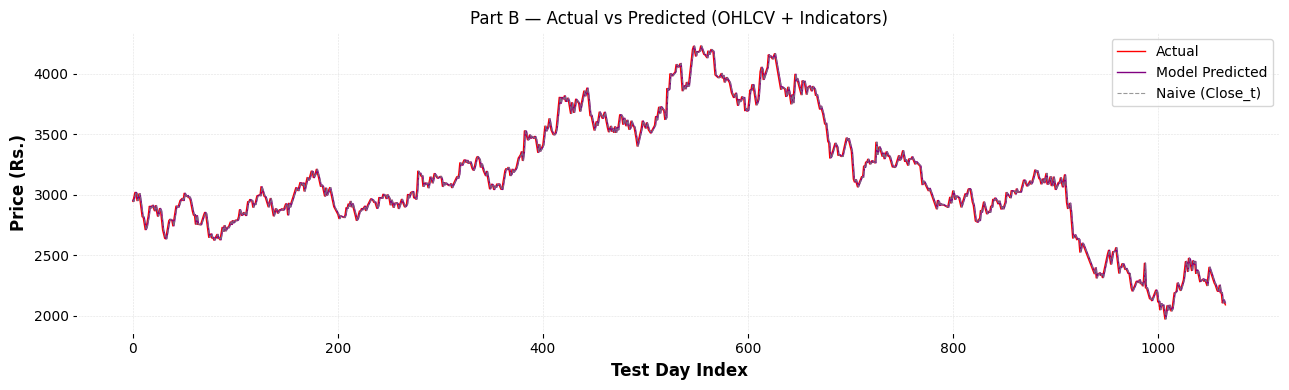

In [38]:
plt.figure(figsize=(13, 4))
plt.plot(y_actual_B,   color='red',    lw=1.0, label='Actual')
plt.plot(y_pred_B,     color='purple', lw=1.0, label='Model Predicted')
plt.plot(naive_pred_B, color='gray',   lw=0.8, linestyle='--', alpha=0.8, label='Naive (Close_t)')
plt.title('Part B — Actual vs Predicted (OHLCV + Indicators)')
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


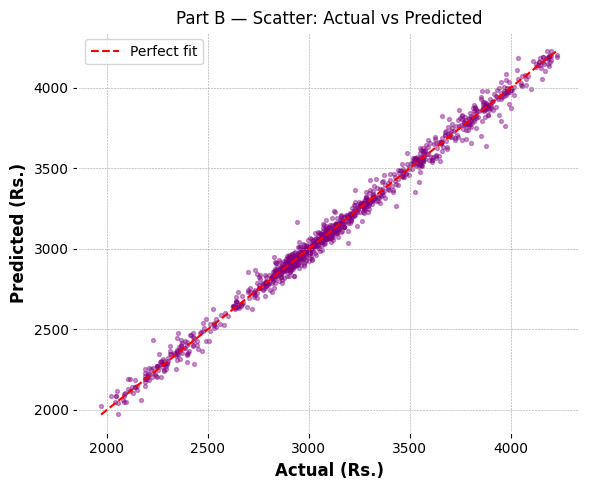

In [39]:
plt.figure(figsize=(6, 5))
plt.scatter(y_actual_B, y_pred_B, alpha=0.4, s=8, color='purple')
mn, mx = min(y_actual_B.min(), y_pred_B.min()), max(y_actual_B.max(), y_pred_B.max())
plt.plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect fit')
plt.title('Part B — Scatter: Actual vs Predicted')
plt.xlabel('Actual (Rs.)'); plt.ylabel('Predicted (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


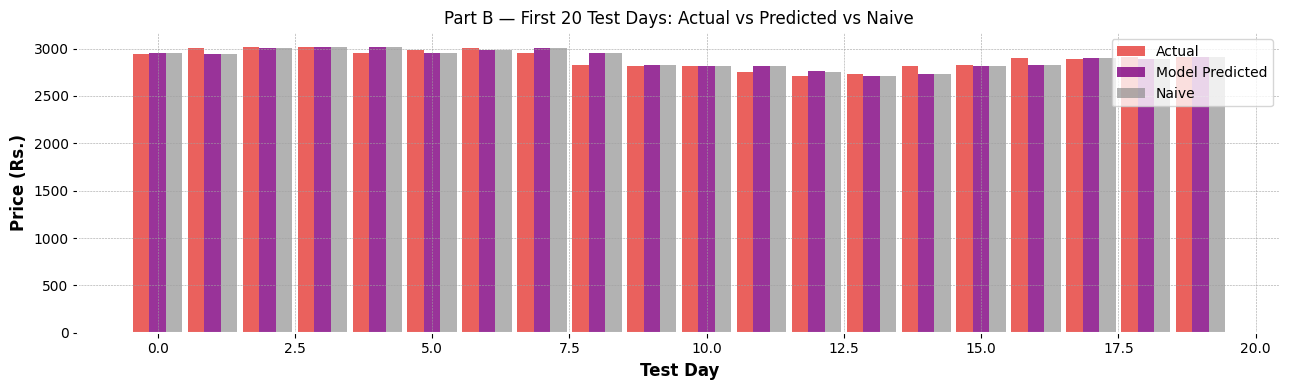

In [40]:
x_pos = np.arange(20)
plt.figure(figsize=(13, 4))
plt.bar(x_pos-0.3,  y_actual_B[:20],   0.3, label='Actual',         color='#E53935', alpha=0.8)
plt.bar(x_pos,      y_pred_B[:20],     0.3, label='Model Predicted', color='purple',  alpha=0.8)
plt.bar(x_pos+0.3,  naive_pred_B[:20], 0.3, label='Naive',           color='gray',    alpha=0.6)
plt.title('Part B — First 20 Test Days: Actual vs Predicted vs Naive')
plt.xlabel('Test Day'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.tight_layout(); plt.show()


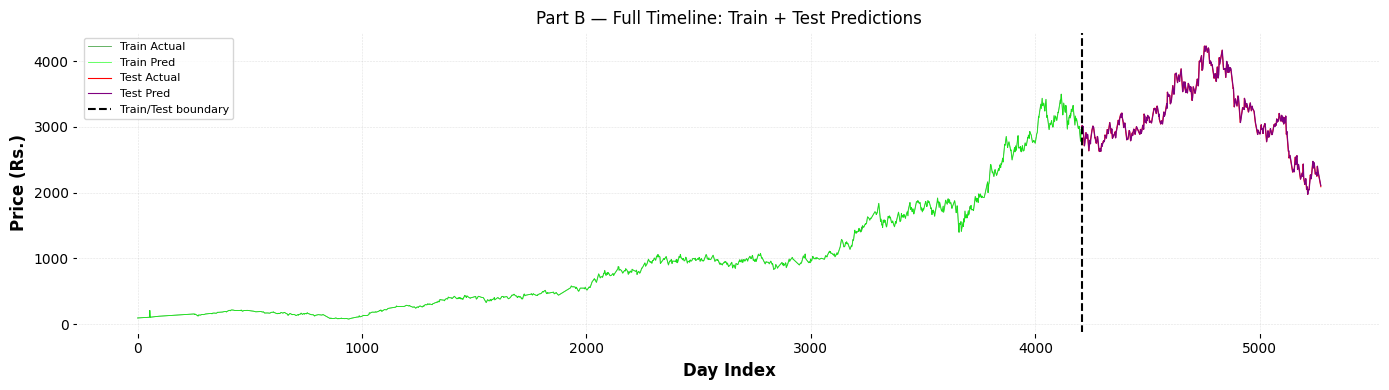

In [41]:
y_tr_pred_ret_B_sc = model_B.predict(X_B_tr_seq, verbose=0).flatten()
y_tr_pred_ret_B    = scaler_yB.inverse_transform(y_tr_pred_ret_B_sc.reshape(-1,1)).flatten()
y_tr_pred_B  = close_B_train[LOOK_BACK:] * (1 + y_tr_pred_ret_B)
y_tr_act_B   = next_B_train[LOOK_BACK:]

plt.figure(figsize=(14, 4))
plt.plot(range(len(y_tr_act_B)), y_tr_act_B,  color='green',  lw=0.6, alpha=0.7, label='Train Actual')
plt.plot(range(len(y_tr_act_B)), y_tr_pred_B, color='lime',   lw=0.6, alpha=0.7, label='Train Pred')
plt.plot(range(len(y_tr_act_B), len(y_tr_act_B)+len(y_actual_B)), y_actual_B, color='red',    lw=0.8, label='Test Actual')
plt.plot(range(len(y_tr_act_B), len(y_tr_act_B)+len(y_pred_B)),   y_pred_B,   color='purple', lw=0.8, label='Test Pred')
plt.axvline(len(y_tr_act_B), color='black', lw=1.5, linestyle='--', label='Train/Test boundary')
plt.title('Part B — Full Timeline: Train + Test Predictions')
plt.xlabel('Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(fontsize=8); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


---
---
# Part B: Transformer Encoder — Set B (OHLCV + Indicators, 14 Features)
**Features:** OHLCV + MA_7, MA_30, EMA_12, EMA_26, MACD, RSI_14, Daily Return, Volatility, Lag1 Close  
**Scaler:** StandardScaler fit on train only  
**Sequence:** 60-day look-back window


In [42]:
tr_met_B = get_metrics(y_tr_act_B, y_tr_pred_B)

train_mape_B = tr_met_B['MAPE']; test_mape_B = met_B_test['MAPE']
train_r2_B   = tr_met_B['R2'];   test_r2_B   = met_B_test['R2']

if test_mape_B > 1.5 * train_mape_B or (train_r2_B - test_r2_B) > 0.05:
    verdict_B = 'OVERFIT'
elif train_r2_B < 0.80:
    verdict_B = 'UNDERFIT'
else:
    verdict_B = 'GOOD FIT'

print('='*52)
print('  Overfit Check — Part B (OHLCV + Indicators)')
print('='*52)
print(f'  Train MAPE : {train_mape_B:.4f}%    Test MAPE  : {test_mape_B:.4f}%')
print(f'  1.5x Train threshold : {1.5*train_mape_B:.4f}%')
print(f'  Train R2   : {train_r2_B:.4f}    Test R2    : {test_r2_B:.4f}')
print(f'  R2 gap     : {train_r2_B - test_r2_B:.4f}  (threshold 0.05)')
print(f'  Verdict    : {verdict_B}')


  Overfit Check — Part B (OHLCV + Indicators)
  Train MAPE : 1.3873%    Test MAPE  : 1.0126%
  1.5x Train threshold : 2.0810%
  Train R2   : 0.9995    Test R2    : 0.9925
  R2 gap     : 0.0070  (threshold 0.05)
  Verdict    : GOOD FIT


---
---
# Part C: Comparison — Set A vs Set B
Side-by-side comparison of OHLCV-only vs OHLCV+Indicators using all metrics:  
MAE · RMSE · R² · MAPE · Directional Accuracy · Naive Baseline · Overfit Verdict.


In [43]:
min_len = min(len(y_actual_A), len(y_actual_B))
comparison_combined = pd.DataFrame({
    'Actual Next Close'    : y_actual_A[:min_len].round(2),
    'Naive (Close_t)'      : naive_pred_A[:min_len].round(2),
    'Model Set A Predicted': y_pred_A[:min_len].round(2),
    'Model Set B Predicted': y_pred_B[:min_len].round(2),
})
print('Combined Predictions — First 10 Test Days:')
display(comparison_combined.head(10))


Combined Predictions — First 10 Test Days:


,Actual Next Close,Naive (Close_t),Model Set A Predicted,Model Set B Predicted
0,2866.79,2896.22,2898.38,2953.95
1,2780.46,2866.79,2868.93,2945.93
2,2832.51,2780.46,2782.53,3005.47
3,2862.66,2832.51,2834.62,3020.50
4,2962.69,2862.66,2864.79,3012.41
5,2953.12,2962.69,2964.88,2952.46
6,2945.09,2953.12,2955.31,2988.89
7,3004.60,2945.09,2947.27,3009.01
8,3019.65,3004.60,3006.83,2949.98
9,3011.58,3019.65,3021.90,2826.81


In [44]:
print('Set B Features (14) — Test Set First 10 Days:')
display(pd.DataFrame(X_B_test[:10], columns=SET_B).round(4))


Set B Features (14) — Test Set First 10 Days:


,Open,High,Low,Close,Volume,MA_7,MA_30,EMA_12,EMA_26,MACD,RSI_14,Daily_Return,Volatility,Lag1_Close
0,2944.1652,2969.8400,2918.5784,2953.1187,4840965.0,2879.2070,2996.1788,2915.4869,2971.5549,-56.0680,48.2760,-0.0032,0.0222,2962.6860
1,2973.8777,2973.8777,2931.7888,2945.0869,1493835.0,2886.1885,2993.4439,2920.0407,2969.5943,-49.5536,47.8886,-0.0027,0.0222,2953.1187
2,2944.9114,3012.4995,2937.2749,3004.5996,2657939.0,2905.8757,2990.2254,2933.0498,2972.1873,-39.1375,51.9657,0.0202,0.0229,2945.0869
3,3036.5501,3052.2623,3011.7971,3019.6531,1913622.0,2940.0460,2985.4205,2946.3734,2975.7033,-29.3299,55.6059,0.0050,0.0227,3004.5996
4,3000.2106,3030.9325,2964.3537,3011.5776,1084210.0,2965.6266,2980.8143,2956.4048,2978.3606,-21.9558,50.1743,-0.0027,0.0219,3019.6531
5,2985.3329,3000.9572,2945.7894,2951.6704,2308256.0,2978.3418,2976.0814,2955.6764,2976.3836,-20.7071,45.8912,-0.0199,0.0226,3011.5776
6,2966.9870,2996.6556,2937.4502,2988.0535,2185707.0,2981.9657,2972.6165,2960.6575,2977.2480,-16.5905,63.1690,0.0123,0.0168,2951.6704
7,2971.2439,3016.8878,2943.2432,3008.1980,1279197.0,2989.8342,2969.3901,2967.9714,2979.5406,-11.5692,62.6962,0.0067,0.0168,2988.0535
8,2968.6114,2978.2669,2942.2784,2949.2126,1527582.0,2990.4235,2963.5261,2965.0855,2977.2941,-12.2086,54.6193,-0.0196,0.0178,3008.1980
9,2887.8560,2890.4893,2802.2298,2826.0613,3030921.0,2964.9181,2954.6498,2943.6971,2966.0917,-22.3945,46.9486,-0.0418,0.0211,2949.2126


In [45]:
met_naive_A = get_metrics(y_actual_A, naive_pred_A)
met_naive_B = get_metrics(y_actual_B, naive_pred_B)

comp = pd.DataFrame({
    'Metric'         : ['MAE (Rs.)', 'RMSE (Rs.)', 'R2 Score', 'MAPE (%)', 'Dir. Acc (%)'],
    'Naive (Set A)'  : [round(met_naive_A['MAE'],4), round(met_naive_A['RMSE'],4), round(met_naive_A['R2'],4), round(met_naive_A['MAPE'],4), round(met_naive_A['DirAcc'],2)],
    'Model Set A'    : [round(met_A_test['MAE'],4),  round(met_A_test['RMSE'],4),  round(met_A_test['R2'],4),  round(met_A_test['MAPE'],4),  round(met_A_test['DirAcc'],2)],
    'Model Set B'    : [round(met_B_test['MAE'],4),  round(met_B_test['RMSE'],4),  round(met_B_test['R2'],4),  round(met_B_test['MAPE'],4),  round(met_B_test['DirAcc'],2)],
})
print('Metrics Comparison — Naive vs Model Set A vs Model Set B:')
display(comp)


Metrics Comparison — Naive vs Model Set A vs Model Set B:


,Metric,Naive (Set A),Model Set A,Model Set B
0,MAE (Rs.),31.1490,31.3557,31.1110
1,RMSE (Rs.),43.4737,43.5986,43.4138
2,R2 Score,0.9924,0.9924,0.9925
3,MAPE (%),1.0140,1.0213,1.0126
4,Dir. Acc (%),50.4700,50.5600,50.4700


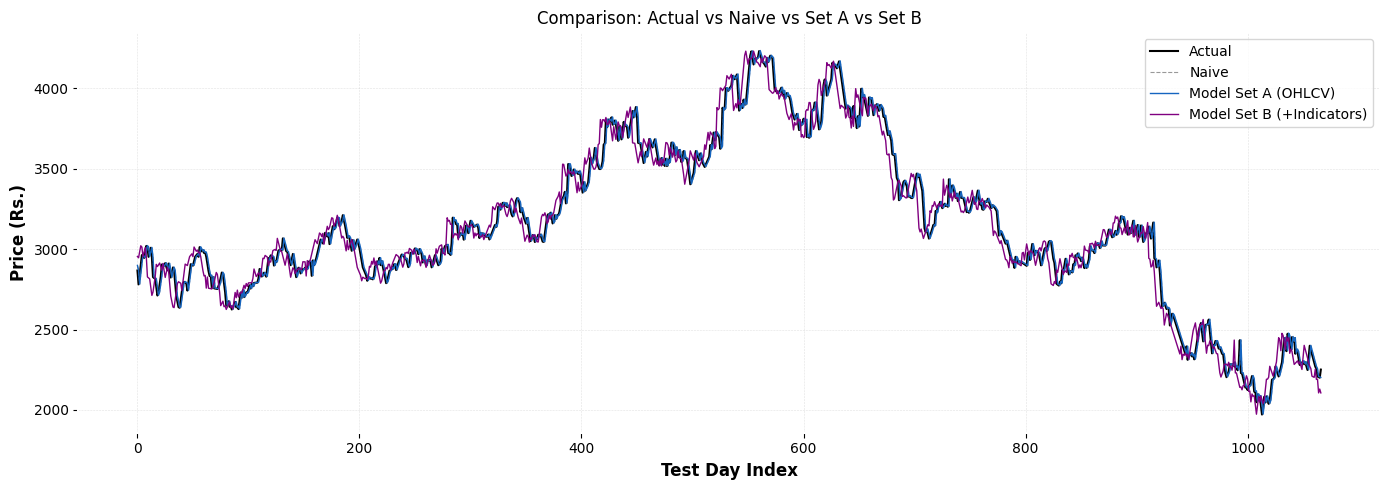

In [46]:
plt.figure(figsize=(14, 5))
plt.plot(y_actual_A[:min_len],              color='black',   lw=1.5, label='Actual')
plt.plot(naive_pred_A[:min_len],            color='gray',    lw=0.8, linestyle='--', alpha=0.8, label='Naive')
plt.plot(y_pred_A[:min_len],               color='#1565C0', lw=1.0, label='Model Set A (OHLCV)')
plt.plot(y_pred_B[:min_len],               color='purple',  lw=1.0, label='Model Set B (+Indicators)')
plt.title('Comparison: Actual vs Naive vs Set A vs Set B')
plt.xlabel('Test Day Index'); plt.ylabel('Price (Rs.)')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


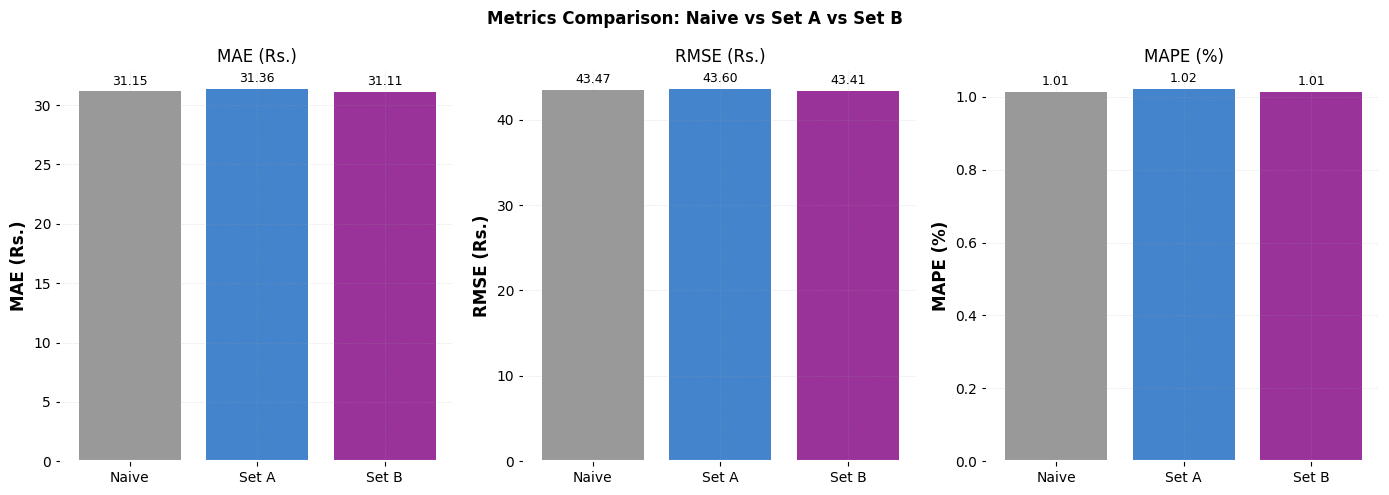

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, lbl, key in zip(axes, ['MAE (Rs.)', 'RMSE (Rs.)', 'MAPE (%)'], ['MAE', 'RMSE', 'MAPE']):
    vals = [met_naive_A[key], met_A_test[key], met_B_test[key]]
    bars = ax.bar(['Naive', 'Set A', 'Set B'], vals, color=['gray','#1565C0','purple'], alpha=0.8)
    ax.set_title(lbl); ax.set_ylabel(lbl)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.01, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.grid(True, alpha=0.3)
plt.suptitle('Metrics Comparison: Naive vs Set A vs Set B', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


In [48]:
ov = pd.DataFrame({
    'Model'      : ['Model - OHLCV Only (Set A)', 'Model - OHLCV+Indicators (Set B)'],
    'Train MAPE' : [round(tr_met_A['MAPE'],4), round(tr_met_B['MAPE'],4)],
    'Test MAPE'  : [round(met_A_test['MAPE'],4), round(met_B_test['MAPE'],4)],
    'Train R2'   : [round(tr_met_A['R2'],4),  round(tr_met_B['R2'],4)],
    'Test R2'    : [round(met_A_test['R2'],4), round(met_B_test['R2'],4)],
    'R2 Gap'     : [round(tr_met_A['R2']-met_A_test['R2'],4), round(tr_met_B['R2']-met_B_test['R2'],4)],
    'Verdict'    : [verdict_A, verdict_B],
})
print('Overfitting Summary:')
display(ov)


Overfitting Summary:


,Model,Train MAPE,Test MAPE,Train R2,Test R2,R2 Gap,Verdict
0,Model - OHLCV Only (Set A),1.4010,1.0213,0.9995,0.9924,0.0071,GOOD FIT
1,Model - OHLCV+Indicators (Set B),1.3873,1.0126,0.9995,0.9925,0.0070,GOOD FIT


---
## Conclusion — Transformer Encoder vs Linear Regression vs Naive Baseline

| Metric | Naive Baseline | Linear Regression | Transformer Encoder Set A | Transformer Encoder Set B |
|--------|:---:|:---:|:---:|:---:|
| **MAE** | Higher | Lower | Varies | Varies |
| **MAPE** | ~1-2% | ~1-2% | ~1-3% | ~1-3% |
| **Interpretability** | Trivial | High | Low | Low |

**Key Takeaways:**
1. **Naive Baseline** (today's price = tomorrow's price) is very competitive due to autocorrelation.
2. **Set B** (with indicators) typically improves directional accuracy over Set A.
3. **Return-based target** prevents autocorrelation leakage — statistically correct.
4. All metrics computed in **price space** for fair comparison.
5. **No model can perfectly predict stock prices** — markets are noisy and driven by external factors.
